# Task 3 — Lago con punto de no retorno

Se estudia un lago con reciclaje interno de nutrientes:

$$\dot{x} = f(x; a) = a - bx + \frac{x^2}{x^2 + 1}$$

- $x(t)$: concentración de nutrientes en el agua.
- $a$: carga externa de nutrientes.
- $b$: tasa de pérdida. **Grupo 10:** $b = 0.52 + 0.03\,(9 \bmod 3) = 0.52$.

En equilibrio, la carga cumple $a = g(x) = bx - \frac{x^2}{x^2+1}$. Un equilibrio es estable si $g'(x^*) > 0$ e inestable si $g'(x^*) < 0$ (demostración en el documento).

Las funciones del modelo se encuentran en `lago.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from lago import (dg, equilibrios, euler_maruyama, g, indicadores_moviles, detrend,
                  rama_clara, raices, rampa_determinista, tendencia_kendall)

B = 0.52
SEMILLA = 42

## Task 3.1. Diagrama de equilibrios

### Puntos de pliegue

Los pliegues son los puntos donde $g'(x) = 0$, es decir, $\frac{2x}{(x^2+1)^2} = b$. Se buscan numéricamente con cambios de signo y el método de Brent.

In [2]:
x_col, x_rec = raices(lambda x: dg(x, B))
a_col, a_rec = g(x_col, B), g(x_rec, B)
print(f"Pliegue 1: x = {x_col:.4f}, a = g(x) = {a_col:.5f}")
print(f"Pliegue 2: x = {x_rec:.4f}, a = g(x) = {a_rec:.5f}")
print(f"Ancho de la región biestable: a_col - a_rec = {a_col - a_rec:.5f}")

Pliegue 1: x = 0.3137, a = g(x) = 0.07353
Pliegue 2: x = 0.9599, a = g(x) = 0.01960
Ancho de la región biestable: a_col - a_rec = 0.05393


**RESULTADOS**

$g'(x) = 0$ en $x = 0.3137$ y $x = 0.9599$

- En $x = 0.3137$, $g$ tiene un máximo local: $a_{col} = 0.07353$ es la **carga de colapso**. Es la mayor carga para la que existe la rama de aguas claras; al superarla, el lago salta a la rama turbia.
- En $x = 0.9599$, $g$ tiene un mínimo local: $a_{rec} = 0.01960$ es la **carga de recuperación**. Es la menor carga para la que existe la rama turbia; solo al bajar de ella el lago regresa a aguas claras.

El ancho de la región biestable es $a_{col} - a_{rec} = 0.05393$.

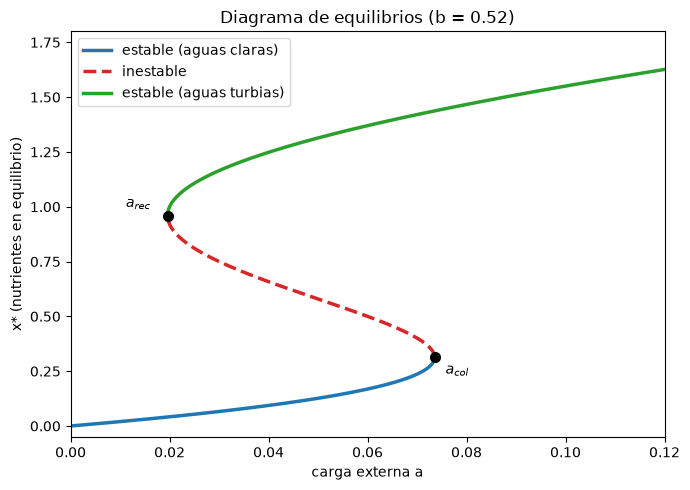

In [3]:
xs = np.linspace(0, 2.2, 2000)
a_eq = g(xs, B)
estable = dg(xs, B) > 0

fig, ax = plt.subplots(figsize=(7, 5))
for mascara, color, nombre in [(estable & (xs < x_col), "tab:blue", "estable (aguas claras)"),
                               (~estable, "tab:red", "inestable"),
                               (estable & (xs > x_rec), "tab:green", "estable (aguas turbias)")]:
    ax.plot(a_eq[mascara], xs[mascara], color=color, lw=2.5, ls="-" if color != "tab:red" else "--", label=nombre)
ax.plot([a_col, a_rec], [x_col, x_rec], "ko", ms=7)
ax.annotate(r"$a_{col}$", (a_col, x_col), xytext=(8, -12), textcoords="offset points")
ax.annotate(r"$a_{rec}$", (a_rec, x_rec), xytext=(-30, 6), textcoords="offset points")
ax.set_xlim(0, 0.12)
ax.set_ylim(-0.05, 1.8)
ax.set_xlabel("carga externa a")
ax.set_ylabel("x* (nutrientes en equilibrio)")
ax.set_title(f"Diagrama de equilibrios (b = {B})")
ax.legend()
plt.tight_layout()
plt.show()

### Verificación con rampas lentas

Se sube $a$ desde $0.005$ hasta $0.09$ con velocidad constante $v$ (RK4, $\Delta t = 0.1$) y luego se baja de $0.09$ a $0.005$. Se registra el valor de $a$ en el que $x$ cruza $0.6$, un valor entre ambas ramas estables. Se usan dos velocidades: $v = 10^{-5}$ (muy lenta) y $v = 10^{-4}$.

In [4]:
A_MIN, A_MAX = 0.005, 0.09
rampas = {}
for v in [1e-5, 1e-4]:
    t_up, a_up, x_up = rampa_determinista(A_MIN, v, (A_MAX - A_MIN) / v, equilibrios(A_MIN, B)[0], B)
    t_dn, a_dn, x_dn = rampa_determinista(A_MAX, -v, (A_MAX - A_MIN) / v, x_up[-1], B)
    a_salto_up = a_up[np.argmax(x_up > 0.6)]
    a_salto_dn = a_dn[np.argmax(x_dn < 0.6)]
    rampas[v] = (a_up, x_up, a_dn, x_dn)
    print(f"v = {v:.0e}: salto al subir en a = {a_salto_up:.5f} (a_col = {a_col:.5f}, diferencia {a_salto_up - a_col:+.5f}) | "
          f"salto al bajar en a = {a_salto_dn:.5f} (a_rec = {a_rec:.5f}, diferencia {a_salto_dn - a_rec:+.5f})")

v = 1e-05: salto al subir en a = 0.07485 (a_col = 0.07353, diferencia +0.00132) | salto al bajar en a = 0.01797 (a_rec = 0.01960, diferencia -0.00163)
v = 1e-04: salto al subir en a = 0.07931 (a_col = 0.07353, diferencia +0.00578) | salto al bajar en a = 0.01258 (a_rec = 0.01960, diferencia -0.00702)


**RESULTADOS**

Con $v = 10^{-5}$ el salto al subir ocurre en $a = 0.07485$ ($+0.00132$ respecto a $a_{col}$) y al bajar en $a = 0.01797$ ($-0.00163$ respecto a $a_{rec}$). Con $v = 10^{-4}$ las diferencias crecen a $+0.00578$ y $-0.00702$.

Los saltos siempre ocurren un poco después del pliegue. Al cruzar el pliegue el equilibrio desaparece, pero cerca de él $\dot{x}$ es casi cero y el sistema tarda en alejarse; mientras tanto, $a$ sigue cambiando. Mientras más rápido cambia $a$, mayor es ese retraso. En el límite $v \to 0$ los saltos coinciden con $a_{col}$ y $a_{rec}$.

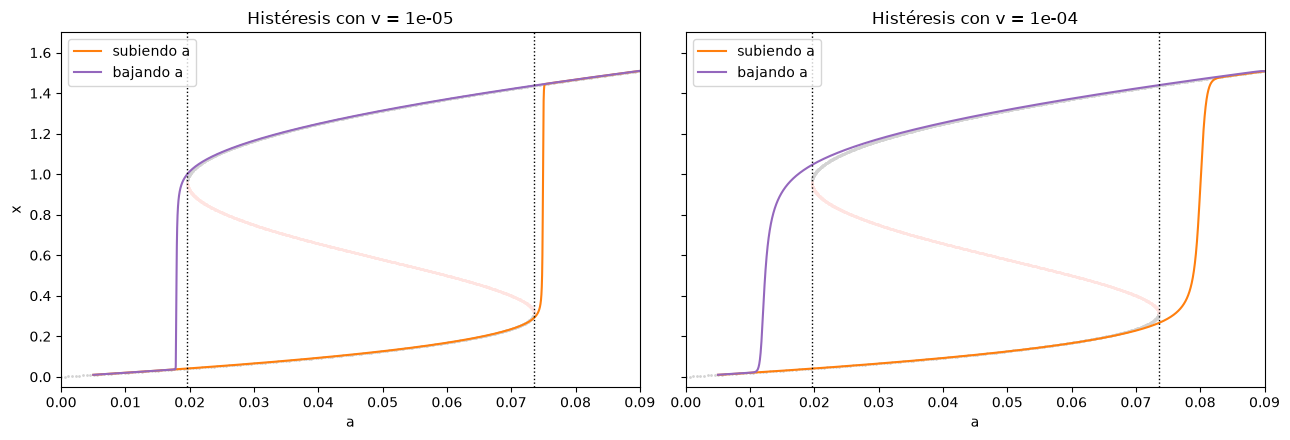

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (v, (a_up, x_up, a_dn, x_dn)) in zip(axes, rampas.items()):
    ax.plot(a_eq[estable], xs[estable], ".", color="lightgray", ms=2)
    ax.plot(a_eq[~estable], xs[~estable], ".", color="mistyrose", ms=2)
    ax.plot(a_up, x_up, color="tab:orange", label="subiendo a")
    ax.plot(a_dn, x_dn, color="tab:purple", label="bajando a")
    ax.axvline(a_col, color="k", ls=":", lw=1)
    ax.axvline(a_rec, color="k", ls=":", lw=1)
    ax.set_xlim(0, A_MAX)
    ax.set_ylim(-0.05, 1.7)
    ax.set_xlabel("a")
    ax.set_title(f"Histéresis con v = {v:.0e}")
    ax.legend(loc="upper left")
axes[0].set_ylabel("x")
plt.tight_layout()
plt.show()

## Task 3.2. Señales de alerta temprana

### Simulación con Euler-Maruyama

Cada paso suma el cambio determinista y un término aleatorio:

$$x_{k+1} = x_k + f(x_k; a(t_k))\,\Delta t + \sigma \sqrt{\Delta t}\,\xi_k, \qquad \xi_k \sim N(0, 1)$$

con $\sigma = 0.01$, $\Delta t = 0.05$ y $a(t) = a_0 + vt$, donde $a_0 = 0.5\,a_{col}$ y $v = (a_{col} - a_0)/2000$. El estado inicial es el equilibrio de aguas claras para $a_0$.

**Salto:** se considera que el sistema saltó cuando $x$ supera la posición del pliegue de colapso, $x = 0.3137$, que es la mayor concentración posible en la rama de aguas claras.

a0 = 0.03677, v = 1.838e-05, x0 = 0.0843
Salto en t = 1817.15, con a = 0.07017 (0.954 a_col)


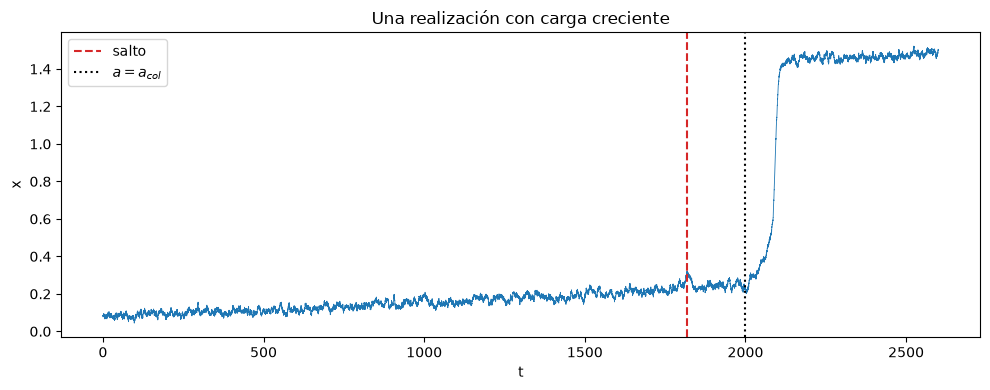

In [6]:
SIGMA, DT, T_COL = 0.01, 0.05, 2000


def simular(sigma, t_col, n_real, rng, rampa=True):
    # Simula n_real realizaciones; con rampa=False la carga queda fija en a0 durante t_col
    a0 = 0.5 * a_col
    v = (a_col - a0) / t_col if rampa else 0.0
    n_pasos = int(1.3 * t_col / DT) if rampa else int(t_col / DT)
    t = np.arange(n_pasos + 1) * DT
    a_t = a0 + v * t
    X = euler_maruyama(equilibrios(a0, B)[0], a_t, B, sigma, DT, n_real, rng)
    return t, a_t, X


def indice_salto(x):
    # Primer índice en que x supera el pliegue de colapso (len(x) si no salta)
    k = np.argmax(x > x_col)
    return k if x[k] > x_col else len(x)


rng = np.random.default_rng(SEMILLA)
t, a_t, X = simular(SIGMA, T_COL, 1, rng)
x = X[0]
k_salto = indice_salto(x)
print(f"a0 = {a_t[0]:.5f}, v = {(a_col - a_t[0]) / T_COL:.3e}, x0 = {x[0]:.4f}")
print(f"Salto en t = {t[k_salto]:.2f}, con a = {a_t[k_salto]:.5f} ({a_t[k_salto] / a_col:.3f} a_col)")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, x, lw=0.6)
ax.axvline(t[k_salto], color="tab:red", ls="--", label="salto")
ax.axvline(T_COL, color="k", ls=":", label=r"$a = a_{col}$")
ax.set_xlabel("t")
ax.set_ylabel("x")
ax.set_title("Una realización con carga creciente")
ax.legend()
plt.tight_layout()
plt.show()

### Indicadores en ventana móvil

- **Eliminación de la tendencia:** se resta un suavizado gaussiano con ancho de 50 unidades de tiempo (1000 puntos). La tendencia, que sigue a $x^*(a(t))$, cambia en escalas de cientos de unidades de tiempo, mientras que las fluctuaciones tienen un tiempo de correlación $1/k$ de entre 3 y 25 unidades. Con ese ancho se quita la tendencia sin borrar las fluctuaciones.
- **Ventana móvil:** la mitad de la serie previa al salto. Con esa ventana cada estimación usa miles de puntos (estimaciones estables) y quedan suficientes ventanas para ver la tendencia.
- **Teoría:** $\text{var} = \sigma^2/(2k)$ y $\text{AC}(\Delta t) = e^{-k\Delta t}$, con $k = g'(x^*(a(t)))$. Cada indicador se grafica en el tiempo final de su ventana.

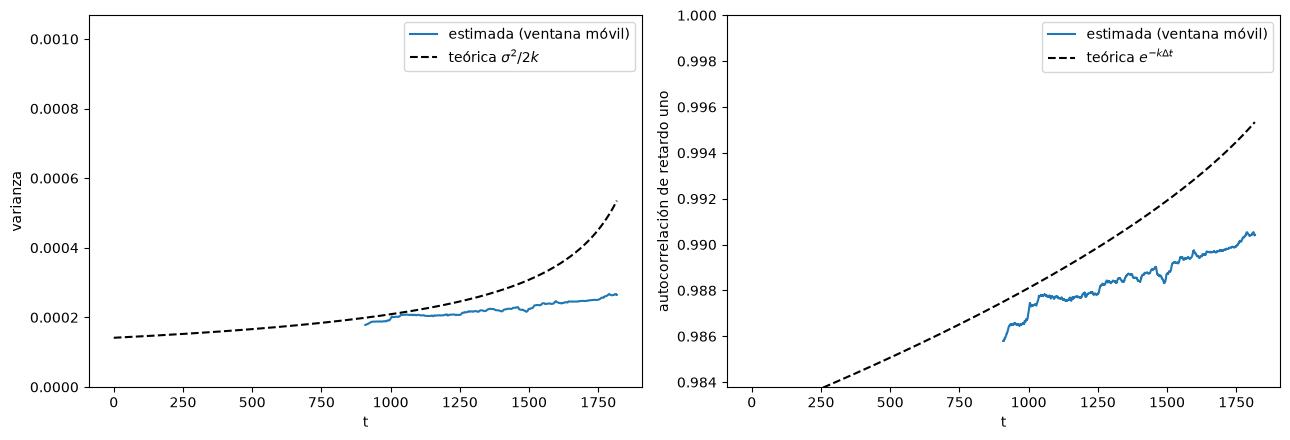

Ventana: 18171 puntos (909 unidades de tiempo)
Varianza: 1.782e-04 -> 2.647e-04 | teórica al final: 5.354e-04
AC1:      0.9858 -> 0.9904 | teórica al final: 0.9953


In [7]:
ANCHO = 1000
serie = x[:k_salto]
ventana = len(serie) // 2
var, ac1 = indicadores_moviles(detrend(serie, ANCHO), ventana)
t_ind = t[ventana - 1:k_salto]

k_teo = dg(rama_clara(a_t[:k_salto], B, x_col), B)
var_teo = SIGMA**2 / (2 * k_teo)
ac_teo = np.exp(-k_teo * DT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(t_ind, var, label="estimada (ventana móvil)")
axes[0].plot(t[:k_salto], var_teo, "k--", label=r"teórica $\sigma^2/2k$")
axes[0].set_ylabel("varianza")
axes[0].set_ylim(0, 4 * var.max())
axes[1].plot(t_ind, ac1, label="estimada (ventana móvil)")
axes[1].plot(t[:k_salto], ac_teo, "k--", label=r"teórica $e^{-k\Delta t}$")
axes[1].set_ylabel("autocorrelación de retardo uno")
axes[1].set_ylim(ac1.min() - 0.002, 1.0)
for ax in axes:
    ax.set_xlabel("t")
    ax.legend()
plt.tight_layout()
plt.show()

print(f"Ventana: {ventana} puntos ({ventana * DT:.0f} unidades de tiempo)")
print(f"Varianza: {var[0]:.3e} -> {var[-1]:.3e} | teórica al final: {var_teo[-1]:.3e}")
print(f"AC1:      {ac1[0]:.4f} -> {ac1[-1]:.4f} | teórica al final: {ac_teo[-1]:.4f}")

**RESULTADOS**

Ambos indicadores suben antes del salto, la varianza pasa de $1.78 \times 10^{-4}$ a $2.65 \times 10^{-4}$ y la autocorrelación de $0.9858$ a $0.9904$. Siguen la forma de la curva teórica, pero quedan por debajo de ella al final por dos motivos: cada valor promedia una ventana de 909 unidades de tiempo (refleja un $k$ promedio, no el del final) y el suavizado gaussiano elimina parte de las fluctuaciones más lentas.

### Tendencia en 100 realizaciones (tau de Kendall)

El tau de Kendall mide si un indicador tiende a subir ($\tau > 0$) o bajar ($\tau < 0$) con el tiempo. Una alerta es **positiva y significativa** si $\tau > 0$ y $p < 0.05$. Para reducir el costo, el tau se calcula con un punto del indicador por unidad de tiempo (uno de cada 20).

In [8]:
N_REAL = 100


def experimento(sigma, t_col, rampa, semilla):
    # Fracción de alertas positivas y significativas en N_REAL realizaciones
    rng = np.random.default_rng(semilla)
    t, a_t, X = simular(sigma, t_col, N_REAL, rng, rampa)
    res, a_salto = [], []
    for x in X:
        k = indice_salto(x)
        a_salto.append(a_t[min(k, len(x) - 1)])
        res.append(tendencia_kendall(x[:k], ANCHO))
    res = np.array(res)
    alerta_var = (res[:, 0] > 0) & (res[:, 1] < 0.05)
    alerta_ac = (res[:, 2] > 0) & (res[:, 3] < 0.05)
    return {"varianza": alerta_var.mean(), "AC1": alerta_ac.mean(), "ambos": (alerta_var & alerta_ac).mean(),
            "τ mediano var": np.median(res[:, 0]), "τ mediano AC1": np.median(res[:, 2]),
            "saltos": np.mean([k < len(x) for k, x in zip(map(indice_salto, X), X)]),
            "a salto / a_col (mediana)": np.median(a_salto) / a_col}


def mostrar(nombre, r):
    print(f"{nombre}: alerta varianza = {r['varianza']:.2f} | alerta AC1 = {r['AC1']:.2f} | ambos = {r['ambos']:.2f} | "
          f"τ mediano var = {r['τ mediano var']:+.2f}, AC1 = {r['τ mediano AC1']:+.2f} | "
          f"fracción que salta = {r['saltos']:.2f} | a del salto / a_col = {r['a salto / a_col (mediana)']:.3f}")


base = experimento(SIGMA, T_COL, True, SEMILLA)
mostrar("Rampa (σ = 0.01, subida en 2000)", base)

Rampa (σ = 0.01, subida en 2000): alerta varianza = 1.00 | alerta AC1 = 1.00 | ambos = 1.00 | τ mediano var = +0.91, AC1 = +0.90 | fracción que salta = 1.00 | a del salto / a_col = 0.985


**RESULTADOS**

En el **100%** de las realizaciones la varianza y la autocorrelación muestran una tendencia positiva y significativa (tau mediano de $0.91$ y $0.90$). El salto ocurre, en mediana, en $a = 0.985\,a_{col}$. El ruido empuja al sistema a la otra cuenca un poco antes del pliegue.

### Control: carga constante $a = 0.5\,a_{col}$

Se repite el procedimiento con la carga fija durante el mismo tiempo ($t = 2000$). Como no hay acercamiento al colapso, cualquier alerta es una falsa alarma.

In [9]:
control = experimento(SIGMA, T_COL, False, SEMILLA + 1)
mostrar("Control (σ = 0.01, a constante, t = 2000)", control)

Control (σ = 0.01, a constante, t = 2000): alerta varianza = 0.46 | alerta AC1 = 0.50 | ambos = 0.44 | τ mediano var = +0.01, AC1 = +0.02 | fracción que salta = 0.00 | a del salto / a_col = 0.500


**RESULTADOS**

Con la carga constante, la varianza da alerta en el **46%** de las realizaciones y la autocorrelación en el **50%**, aunque el tau mediano es casi cero ($+0.01$ y $+0.02$).

**Interpretación:** el indicador detecta casi siempre la transición (100%), pero también da alerta en cerca de la mitad de los lagos que no se acercan al colapso. Como alarma, una tasa de falsas alarmas tan alta lo vuelve poco confiable. La causa es que la prueba de Kendall supone puntos independientes, mientras que los indicadores de ventanas móviles que se traslapan están muy correlacionados; cualquier subida o bajada lenta por azar resulta "significativa". La diferencia real entre ambos casos está en la magnitud de tau ($0.91$ contra $0.01$), no en el valor $p$.

### Sensibilidad: más ruido y subida más rápida

In [10]:
casos = {
    "Rampa, σ = 0.02": experimento(0.02, T_COL, True, SEMILLA + 2),
    "Control, σ = 0.02": experimento(0.02, T_COL, False, SEMILLA + 3),
    "Rampa, subida en 1000": experimento(SIGMA, T_COL / 2, True, SEMILLA + 4),
    "Control, t = 1000": experimento(SIGMA, T_COL / 2, False, SEMILLA + 5),
}
mostrar("Rampa, σ = 0.01 (base)", base)
mostrar("Control, σ = 0.01 (base)", control)
for nombre, r in casos.items():
    mostrar(nombre, r)

Rampa, σ = 0.01 (base): alerta varianza = 1.00 | alerta AC1 = 1.00 | ambos = 1.00 | τ mediano var = +0.91, AC1 = +0.90 | fracción que salta = 1.00 | a del salto / a_col = 0.985
Control, σ = 0.01 (base): alerta varianza = 0.46 | alerta AC1 = 0.50 | ambos = 0.44 | τ mediano var = +0.01, AC1 = +0.02 | fracción que salta = 0.00 | a del salto / a_col = 0.500
Rampa, σ = 0.02: alerta varianza = 1.00 | alerta AC1 = 1.00 | ambos = 1.00 | τ mediano var = +0.84, AC1 = +0.84 | fracción que salta = 1.00 | a del salto / a_col = 0.912
Control, σ = 0.02: alerta varianza = 0.40 | alerta AC1 = 0.40 | ambos = 0.38 | τ mediano var = -0.20, AC1 = -0.20 | fracción que salta = 0.00 | a del salto / a_col = 0.500
Rampa, subida en 1000: alerta varianza = 0.99 | alerta AC1 = 0.99 | ambos = 0.99 | τ mediano var = +0.87, AC1 = +0.86 | fracción que salta = 1.00 | a del salto / a_col = 0.998
Control, t = 1000: alerta varianza = 0.50 | alerta AC1 = 0.48 | ambos = 0.47 | τ mediano var = +0.06, AC1 = +0.03 | fracción q

**RESULTADOS**

| Caso | Alerta var | Alerta AC1 | $\tau$ mediano (var, AC1) | Salto en $a/a_{col}$ | Falsas alarmas (var, AC1) |
|---|---|---|---|---|---|
| Base ($\sigma = 0.01$, subida en 2000) | 1.00 | 1.00 | 0.91, 0.90 | 0.985 | 0.46, 0.50 |
| $\sigma = 0.02$ | 1.00 | 1.00 | 0.84, 0.84 | 0.912 | 0.40, 0.40 |
| Subida en 1000 | 0.99 | 0.99 | 0.87, 0.86 | 0.998 | 0.50, 0.48 |


- **Duplicar $\sigma$:** la varianza teórica $\sigma^2/(2k)$ se multiplica por 4 en todo momento, pero su tendencia depende solo de $k$, y la autocorrelación $e^{-k\Delta t}$ no depende de $\sigma$. El efecto principal es que el ruido más grande saca al sistema de la cuenca antes ($0.912\,a_{col}$ contra $0.985\,a_{col}$), cuando $k$ todavía no es pequeño. Se observa menos parte del aumento de los indicadores y el tau baja ($0.84$). La tasa de falsas alarmas sigue siendo alta (40%).

- **Subir en la mitad del tiempo:** la teoría supone que $a$ cambia lento comparado con el tiempo de recuperación $1/k$. Al subir más rápido, el sistema se queda atrás del equilibrio y cada ventana abarca un rango mayor de $a$, por lo que las estimaciones son más ruidosas y el tau baja ($0.87$). Además, el sistema llega más cerca del pliegue antes de saltar ($0.998\,a_{col}$), porque el ruido tiene menos tiempo para sacarlo antes. La detección se mantiene (99%) y las falsas alarmas también (cerca de 50%).